# 21b · Retina revisions, review cycle 1, part 2 (post hoc)

**Status: post hoc, requested in review.** Reads only frozen v2 predictions; changes no locked result; writes aggregates only.

| Section | Review point | What it does |
|---|---|---|
| R5 | 4.2 | **Patient-disjoint local partner choice** in EyePACS (22-model zoo, as in the original) and DDR (11 designs; filename groups as the unit). Calibration severe and other images are drawn from whole patients (groups), every image of those patients is removed from evaluation, and ranks and referral sets are rebuilt on the evaluation images. Reports the share of the gain from the strongest standalone partner and from the best possible partner (both over random choice), and the number of unique patients with severe DR needed. |
| R6 | 5.4 | **Out-of-sample harm tuning.** Patients (groups) are split in half at random; each arm (each single system and each pair) chooses its referral share on one half and is scored at that share on the other half, and the halves are then swapped; 50 random splits. Shares run from 0% (refer no one) to 100% (refer everyone). Three comparators: the average member; the member that did better on the calibration half (a choice a programme could make); and the better member on the evaluation half (hindsight). The in-sample oracle version is reported alongside so the optimism can be read directly. Intervals are the 2.5th and 97.5th percentiles across splits. |

**Runtime:** CPU, High-RAM, about 30 to 60 minutes.

In [1]:
# --- setup ---
from google.colab import drive
drive.mount("/content/drive")
import os, re, json, hashlib, itertools, datetime, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata
BASE = "/content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2"
PREDS, SPLITS, RESULTS, FIGS = (f"{BASE}/{d}" for d in ("03_predictions", "01_splits", "04_results", "05_figures"))
BRSET_LABELS = "/content/drive/MyDrive/stochastic_orthogonality/data/brset/label_brset.csv"
OUTD = f"{RESULTS}/revisions_c1"; os.makedirs(OUTD, exist_ok=True)
OUT_JSON = f"{OUTD}/retina_revisions_c1_b.json"
assert not os.path.exists(OUT_JSON), "this secondary analysis has already been written; rename the old output deliberately to rerun"
def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
ARCHS = ["densenet121_binary", "densenet121_5class", "efficientnet_b3_binary", "efficientnet_b3_5class", "resnet50_binary", "resnet50_5class",
         "vit_base_binary", "vit_base_5class", "retfound_binary", "retfound_5class", "retfound_adversarial"]
SEEDS = [0, 1, 2]; PAIRS = list(itertools.combinations(ARCHS, 2))
def tag(k): return "" if k == 0 else f"_seed{k}"
MODELS = [(a, k) for a in ARCHS for k in SEEDS]
B, SEED = 1000, 20261028
VOLS = np.round(np.arange(0.01, 0.701, 0.01), 2)

# harm model (severe visual loss events per missed eye, one-year delay)
PDR = {"low": 0.02, "central": 0.0475, "high": 0.075}
P_HR_G3, DIRECT_G3 = 0.15, 0.002
P_PDR_G2 = {"low": 0.02, "central": 0.04, "high": 0.08}
SY = {"low": 10, "central": 15, "high": 20}; QALY_PER_BLIND_YEAR = 0.214
def svl(grade, sc):
    r = PDR[sc]
    return np.select([grade == 4, grade == 3, grade == 2], [r, P_HR_G3 * 0.5 * r + DIRECT_G3, P_PDR_G2[sc] * 0.5 * r], 0.0)
KS = np.round(np.geomspace(10, 10000, 31), 1)          # false referrals one prevented severe visual loss event is worth
LAMBDAS = np.round(np.geomspace(1e-4, 3e-2, 25), 6); BAND = (0.001, 0.004); LAM_ANCHOR = 0.0025
NPJ_GRID = {"miss": [[500, 200, 15], [250, 100, 10], [1000, 400, 20], [100, 50, 10], [50, 25, 5]], "wfp": [1, 5, 20, 50, 100]}
for sc in ("low", "central", "high"):
    print(f"{sc:>7}: per missed eye, severe visual loss events  g4 {svl(np.array(4), sc):.4f}  g3 {svl(np.array(3), sc):.4f}  g2 {svl(np.array(2), sc):.5f}"
          f"  | QALY per event {SY[sc] * QALY_PER_BLIND_YEAR:.2f}")
CORE4 = ["densenet121_5class", "efficientnet_b3_5class", "resnet50_5class", "retfound_5class"]
FULL = f"{BASE}/04_results/ballistics_full"


Mounted at /content/drive
    low: per missed eye, severe visual loss events  g4 0.0200  g3 0.0035  g2 0.00020  | QALY per event 2.14
central: per missed eye, severe visual loss events  g4 0.0475  g3 0.0056  g2 0.00095  | QALY per event 3.21
   high: per missed eye, severe visual loss events  g4 0.0750  g3 0.0076  g2 0.00300  | QALY per event 4.28


## 1. Load (frozen predictions only)

In [2]:
def pick(cols, pats, what):
    m = [c for c in cols if any(re.fullmatch(p, c, flags=re.I) for p in pats)]
    assert len(m) == 1, f"cannot identify the {what} column; columns are {list(cols)}"
    return m[0]
F_OVERRIDE = {}   # e.g. {"ddr": 0.56} if the printed f differs from the locked value
def norm(x): return pd.Series(x, dtype=str).str.replace(r"\.(jpe?g|png|tiff?)$", "", regex=True, flags=re.I).to_numpy()
HASHES = {}
def load_preds(fmt, key="image_id"):
    P = {}; ref = None
    for a, k in MODELS:
        fn = f"{PREDS}/{fmt.format(arch=a, tag=tag(k))}"; HASHES[os.path.basename(fn)] = sha256_file(fn)
        d = pd.read_csv(fn, dtype={key: str})
        if ref is None: ref = d
        else: assert (d[key].values == ref[key].values).all(), f"row order differs in {os.path.basename(fn)}"
        P[(a, k)] = d["predicted_probability"].to_numpy(np.float64)
    return ref, P
POP = {}
# EyePACS fresh set (labels and patients travel with the prediction files)
ref, P = load_preds("eyepacs_predictions_fresh_{arch}{tag}_v2.csv")
POP["eyepacs"] = {"grade": ref.true_grade.to_numpy(int), "group": ref.patient_id.astype(str).to_numpy(), "P": P, "f": 0.25}
# DDR (labels and filename groups from the intraset split written before inference)
ref, P = load_preds("ddr_predictions_{arch}{tag}_v2.csv")
sp = pd.read_csv(f"{SPLITS}/ddr_split_intraset_v2.csv", dtype={"image_id": str})
gcol, grpcol = pick(sp.columns, ["grade", "true_grade", "dr_grade", "level"], "DDR grade"), pick(sp.columns, ["group", "filename_group", "group_id"], "DDR group")
sp["_k"] = norm(sp["image_id"]); sp = sp.set_index("_k").loc[norm(ref.image_id)]
half = [c for c in sp.columns if re.fullmatch("half|split|subset", c, flags=re.I)]
g = sp[gcol].to_numpy(int); keep = g <= 4
if half:
    isA = sp[half[0]].astype(str).str.strip().str.upper().isin(["A", "HALF_A", "HALFA", "0"]).to_numpy()
    print("DDR half column:", half[0], "| values:", sorted(sp[half[0]].astype(str).unique())[:6], "| treated as half A:", int((isA & keep).sum()), "eyes")
else:
    isA = np.ones(len(g), bool); print("WARNING: no DDR half column found; f uses the whole DDR prevalence")
prevA = float((g[keep & isA] >= 2).mean())
POP["ddr"] = {"grade": g[keep], "group": sp[grpcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}, "f": round(1.31 * prevA, 4)}
# BRSET (labels read from the BRSET label file; only aggregates leave this runtime)
ref, P = load_preds("brset_predictions_eyepacs_{arch}{tag}_v2.csv")
lb = pd.read_csv(BRSET_LABELS, dtype=str)
icol, pcol, idcol = pick(lb.columns, [r".*icdr.*"], "BRSET ICDR grade"), pick(lb.columns, ["patient_id", "patient"], "BRSET patient"), pick(lb.columns, ["image_id", "image"], "BRSET image id")
lb["_k"] = norm(lb[idcol]); lb = lb.set_index("_k").loc[norm(ref.image_id)]
g = pd.to_numeric(lb[icol], errors="coerce").to_numpy(); keep = np.isin(g, [0, 1, 2, 3, 4])
POP["brset"] = {"grade": g[keep].astype(int), "group": lb[pcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}}
POP["brset"]["f"] = round(1.31 * float((POP["brset"]["grade"] >= 2).mean()), 4)
for name, v in F_OVERRIDE.items(): POP[name]["f"] = v
for name, d in POP.items():
    gr = d["grade"]
    print(f"{name:>8}: {len(gr):,} eyes | {len(set(d['group'])):,} groups | referable {np.mean(gr >= 2):.3f} | grade 3 {int((gr == 3).sum())} | grade 4 {int((gr == 4).sum())} | f = {d['f']}")
print("expected f from the manuscript: DDR about 0.56 (from half A), BRSET about 0.075")
ids_e = pd.read_csv(f"{PREDS}/eyepacs_predictions_fresh_{ARCHS[0]}_v2.csv", dtype={"image_id": str}).image_id.to_numpy()
ZOO_CKPT = {'resnet50': 'resnet50_a1_in1k', 'resnet50_swsl': 'resnet50_swsl', 'resnext50': 'resnext50', 'regnety_032': 'regnety_032', 'densenet121': 'densenet121_in1k',
            'efficientnet_b3': 'effb3_in1k', 'effnetv2_s': 'effnetv2_s', 'mobilenetv3': 'mobilenetv3', 'convnext_t': 'convnext_t_in1k', 'convnext_t22k': 'convnext_t_in22k',
            'inception_v3': 'inception_v3', 'vgg16_bn': 'vgg16_bn', 'vit_b': 'vitb_sup_in21k', 'vit_b_mae': 'vitb_mae', 'vit_b_dinov2': 'vitb_dinov2', 'vit_b_clip': 'vitb_clip',
            'vit_s': 'vits_in21k', 'deit_s': 'deit_s', 'swin_t': 'swin_t', 'beitv2_b': 'beitv2_b', 'mixer_b16': 'mixer_b16', 'retfound': 'retfound'}
CKPT = {'densenet121': 'densenet121_in1k', 'efficientnet_b3': 'effb3_in1k', 'resnet50': 'resnet50_a1_in1k', 'vit_base': 'vitb_sup_in21k', 'retfound': 'retfound'}
def paper_ckpt(v): return next(c for p, c in CKPT.items() if v.startswith(p))
ZOO = {}
for z in ZOO_CKPT:
    df = pd.read_csv(f"{FULL}/preds/{z}_fresh.csv", dtype={"image_id": str}); pc = next(c for c in ("predicted_probability", "probability", "prob") if c in df.columns)
    s = df.drop_duplicates("image_id").set_index("image_id")[pc].astype(float).reindex(ids_e); assert s.notna().all(), z; ZOO[z] = s.to_numpy()
print("EyePACS zoo models:", len(ZOO))


DDR half column: half | values: ['A', 'B'] | treated as half A: 6205 eyes
 eyepacs: 15,794 eyes | 7,897 groups | referable 0.195 | grade 3 384 | grade 4 328 | f = 0.25
     ddr: 12,422 eyes | 332 groups | referable 0.453 | grade 3 236 | grade 4 913 | f = 0.555
   brset: 16,266 eyes | 8,524 groups | referable 0.057 | grade 3 78 | grade 4 396 | f = 0.0745
expected f from the manuscript: DDR about 0.56 (from half A), BRSET about 0.075
EyePACS zoo models: 22


In [3]:

def refer(s, f):
    r = np.zeros(len(s), bool); r[np.argsort(-s, kind="stable")[:int(round(f * len(s)))]] = True; return r
def rk(s): return rankdata(s) / len(s)
def pairscore(ra, rb): return np.maximum(ra, rb) + 1e-9 * np.minimum(ra, rb)
def boot_w(groups, B, seed):
    codes = pd.factorize(groups)[0]; G = codes.max() + 1; rng = np.random.default_rng(seed)
    W = np.empty((B + 1, len(codes)), np.float32); W[0] = 1.0
    for b in range(1, B + 1): W[b] = np.bincount(rng.integers(0, G, G), minlength=G)[codes]
    return W
def ci(x):
    x = np.asarray(x, float); f = x[1:][np.isfinite(x[1:])]
    return [float(x[0]), float(np.percentile(f, 2.5)) if len(f) else None, float(np.percentile(f, 97.5)) if len(f) else None]
def ratio_ci(num, den):
    r = np.where(den > 0, num / np.where(den > 0, den, 1), np.inf)
    return float(r[0]), float(np.percentile(r[1:], 2.5)), float(np.percentile(r[1:], 97.5)), float(np.mean(~np.isfinite(r[1:])))
def fmt(t, d=2): return f"{t[0]:.{d}f} ({t[1]:.{d}f} to {t[2]:.{d}f})"
REC = {"status": "secondary and exploratory analyses requested in review cycle 1 (Astra, 29 Oct 2026); post hoc; no lock",
       "written_utc": None, "bootstrap_resamples": B}
print("helpers ready")


helpers ready


## R5. Patient-disjoint local partner choice
For each first system, candidates are systems not built from the same pretrained checkpoint (as in the original analysis). A draw takes patients with severe DR (grade 3 or 4) in random order until k severe images are available, and patients without severe DR until k other images are available; the calibration sample is those 2k images. Every image of every drawn patient is then excluded. On the remaining images, each system's ranks and referral set and each pair's referral set are rebuilt. The chosen partner is the candidate with the highest AUC (severe against other) on the calibration sample. Outcomes on the evaluation images, averaged over first systems and 200 draws:
- net severe misses rescued by the chosen partner, by a random candidate, by the strongest standalone candidate on the evaluation images, and by the best possible candidate for that first system (oracle);
- shares: (chosen − random) / (strongest − random) and (chosen − random) / (oracle − random).

In [4]:
from sklearn.metrics import roc_auc_score
SITES5 = {"EyePACS": {"grade": POP["eyepacs"]["grade"], "group": POP["eyepacs"]["group"], "f": 0.25, "S": ZOO, "ckpt": ZOO_CKPT},
          "DDR": {"grade": POP["ddr"]["grade"], "group": POP["ddr"]["group"], "f": POP["ddr"]["f"], "S": {a: POP["ddr"]["P"][(a, 0)] for a in ARCHS}, "ckpt": {a: paper_ckpt(a) for a in ARCHS}}}
old5 = json.load(open(f"{RESULTS}/sibling_detector_results.json"))["A_checkpoint_rule_enriched"]
RNG5 = np.random.default_rng(20261031); DRAWS5 = 200; R5 = {}
for site, S in SITES5.items():
    t0 = time.time(); g = S["grade"]; sev = g >= 3; M = list(S["S"]); pid = pd.factorize(S["group"])[0]; npat = pid.max() + 1
    elig = {a: [b for b in M if b != a and S["ckpt"][b] != S["ckpt"][a]] for a in M}
    upairs = sorted({tuple(sorted((a, b))) for a in M for b in elig[a]})
    sev_pat = np.unique(pid[sev]); non_pat = np.setdiff1d(np.arange(npat), sev_pat); R5[site] = {}
    for k in (25, 50, 100, 200):
        out = {r: [] for r in ("enriched_auc", "random", "true_strongest", "oracle")}; nsevpat = []
        for _ in range(DRAWS5):
            chosen_s, nimg = [], 0
            for p_ in RNG5.permutation(sev_pat):
                chosen_s.append(p_); nimg += int((sev & (pid == p_)).sum())
                if nimg >= k: break
            chosen_n, nimg2 = [], 0
            for p_ in RNG5.permutation(non_pat):
                chosen_n.append(p_); nimg2 += int((pid == p_).sum())
                if nimg2 >= k: break
            si = RNG5.permutation(np.flatnonzero(sev & np.isin(pid, chosen_s)))[:k]; ni = RNG5.permutation(np.flatnonzero(np.isin(pid, chosen_n)))[:k]
            cal = np.r_[si, ni]; ycal = np.r_[np.ones(len(si)), np.zeros(len(ni))]
            ev = ~np.isin(pid, np.r_[chosen_s, chosen_n]); se = sev[ev]; nsevpat.append(len(chosen_s))
            auc = {b: roc_auc_score(ycal, S["S"][b][cal]) for b in M}
            Rv = {m: refer(S["S"][m][ev], S["f"]) for m in M}; Kv = {m: rk(S["S"][m][ev]) for m in M}
            am = {m: int((se & ~Rv[m]).sum()) for m in M}
            em = {pq: int((se & ~refer(pairscore(Kv[pq[0]], Kv[pq[1]]), S["f"])).sum()) for pq in upairs}
            vals = {r: [] for r in out}
            for a in M:
                sc = {b: am[a] - em[tuple(sorted((a, b)))] for b in elig[a]}
                vals["random"].append(np.mean(list(sc.values()))); vals["oracle"].append(max(sc.values()))
                vals["true_strongest"].append(sc[min(elig[a], key=lambda b: am[b])]); vals["enriched_auc"].append(sc[max(elig[a], key=lambda b: auc[b])])
            for r in out: out[r].append(np.mean(vals[r]))
        mu = {r: float(np.mean(v)) for r, v in out.items()}
        R5[site][k] = {"share_of_strongest_partner_gain": round((mu["enriched_auc"] - mu["random"]) / (mu["true_strongest"] - mu["random"]), 3) if mu["true_strongest"] != mu["random"] else None,
                       "share_of_oracle_gain": round((mu["enriched_auc"] - mu["random"]) / (mu["oracle"] - mu["random"]), 3) if mu["oracle"] != mu["random"] else None,
                       "mean_net_severe_rescued": {r: round(v, 2) for r, v in mu.items()}, "mean_unique_patients_with_severe_drawn": round(float(np.mean(nsevpat)), 1),
                       "image_split_original": old5.get(site, {}).get(str(k))}
        print(site, k, {kk: vv for kk, vv in R5[site][k].items() if kk != "image_split_original"}, f"({time.time() - t0:.0f}s)")
REC["R5_patient_disjoint_partner_choice"] = R5

EyePACS 25 {'share_of_strongest_partner_gain': 0.402, 'share_of_oracle_gain': 0.3, 'mean_net_severe_rescued': {'enriched_auc': 13.78, 'random': 11.2, 'true_strongest': 17.61, 'oracle': 19.78}, 'mean_unique_patients_with_severe_drawn': 15.3} (110s)
EyePACS 50 {'share_of_strongest_partner_gain': 0.526, 'share_of_oracle_gain': 0.388, 'mean_net_severe_rescued': {'enriched_auc': 13.68, 'random': 10.45, 'true_strongest': 16.59, 'oracle': 18.78}, 'mean_unique_patients_with_severe_drawn': 30.3} (221s)
EyePACS 100 {'share_of_strongest_partner_gain': 0.749, 'share_of_oracle_gain': 0.553, 'mean_net_severe_rescued': {'enriched_auc': 13.68, 'random': 9.37, 'true_strongest': 15.13, 'oracle': 17.17}, 'mean_unique_patients_with_severe_drawn': 60.2} (330s)
EyePACS 200 {'share_of_strongest_partner_gain': 0.786, 'share_of_oracle_gain': 0.555, 'mean_net_severe_rescued': {'enriched_auc': 11.14, 'random': 7.39, 'true_strongest': 12.16, 'oracle': 14.14}, 'mean_unique_patients_with_severe_drawn': 120.0} (439s

## R6. Out-of-sample harm tuning
Harm models as in notebooks 18 and 18b: literature-weighted severe visual loss (central) and every missed severe eye counted as lost. A false referral (grade 0 or 1) costs 1/K of one event. For each split and direction, every arm picks the share (0% to 100% in steps of 1%) that minimises its cost on the calibration half; the cost is then measured at that share on the evaluation half. Advantage is comparator minus pair, per 10,000 eyes; above zero the pair is ahead. Also reported: how often an arm picked 0% or 100% (boundary), and the in-sample oracle advantage on the evaluation half.

  eyepacs: split 1 (7s)
  eyepacs: split 10 (68s)
  eyepacs: split 50 (336s)
eyepacs lit_central: advantage (mean over splits) at K = 100 / 1,000 / 10,000: {'average': [0.533, 0.327, 0.073], 'better_on_calibration': [0.168, 0.166, 0.065], 'better_hindsight': [0.126, 0.133, 0.032], 'oracle_better_hindsight': [0.142, 0.131, 0.035], 'oracle_average': [0.54, 0.312, 0.063]}
eyepacs allblind: advantage (mean over splits) at K = 100 / 1,000 / 10,000: {'average': [5.367, 0.511, 0.023], 'better_on_calibration': [3.452, 0.678, 0.197], 'better_hindsight': [2.297, -0.345, -0.464], 'oracle_better_hindsight': [2.415, 0.19, 0.017], 'oracle_average': [5.191, 0.633, 0.032]}
  ddr: split 1 (5s)
  ddr: split 10 (50s)
  ddr: split 50 (244s)
ddr lit_central: advantage (mean over splits) at K = 100 / 1,000 / 10,000: {'average': [1.217, 0.418, -0.017], 'better_on_calibration': [0.512, 0.238, 0.003], 'better_hindsight': [0.299, 0.105, -0.066], 'oracle_better_hindsight': [0.43, 0.209, 0.008], 'oracle_average':

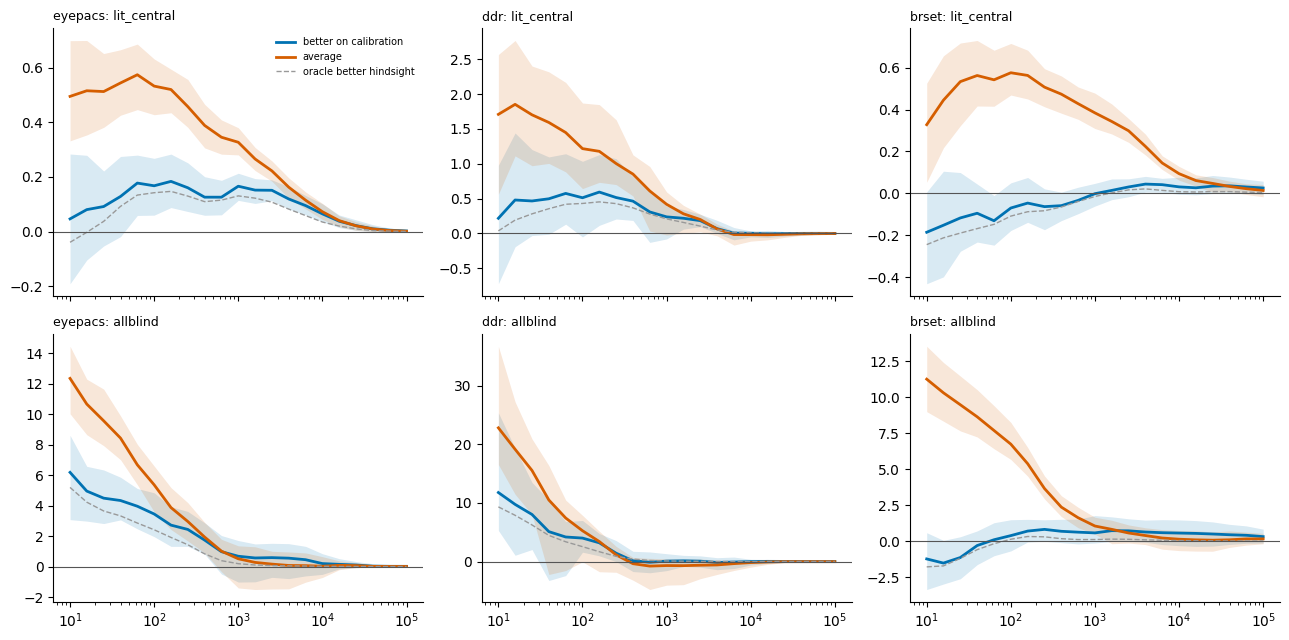

In [5]:
VOLS6 = np.round(np.arange(0, 1.0001, 0.01), 2); KS6 = np.round(np.geomspace(10, 1e5, 21), 1); NS6 = 50
def harm6(gr): return {"lit_central": svl(gr, "central"), "allblind": np.select([gr >= 3, gr == 2], [1.0, svl(np.array(2), "high")], 0.0)}
def cost_curves(score, hv, fp):
    """cost per 10k at every share in VOLS6 and every K: array (vols, K)"""
    n = len(score); o = np.argsort(-score, kind="stable"); kpos = np.round(VOLS6 * n).astype(int)
    ch = np.r_[0, np.cumsum(hv[o])]; cf = np.r_[0, np.cumsum(fp[o])]
    miss_h = ch[-1] - ch[kpos]; fps_ = cf[kpos]
    return (miss_h[:, None] + fps_[:, None] / KS6[None, :]) / n * 1e4
R6 = {}
for name, d in POP.items():
    t0 = time.time(); gr = d["grade"]; codes = pd.factorize(d["group"])[0]; G = codes.max() + 1; rng = np.random.default_rng(SEED + 17)
    H = harm6(gr); fp = (gr <= 1).astype(float); res = {h: {c: [] for c in ("average", "better_on_calibration", "better_hindsight", "oracle_better_hindsight", "oracle_average")} for h in H}
    boundary = {h: [] for h in H}
    for s in range(NS6):
        half = rng.permutation(G) < G // 2; hmask = half[codes]
        for cal_m, ev_m in ((hmask, ~hmask), (~hmask, hmask)):
            for h, hv in H.items():
                Cc, Ce = {}, {}
                for m, p in d["P"].items():
                    Cc[m] = cost_curves(rk(p[cal_m]), hv[cal_m], fp[cal_m]); Ce[m] = cost_curves(rk(p[ev_m]), hv[ev_m], fp[ev_m])
                kc = {m: rk(p[cal_m]) for m, p in d["P"].items()}; ke = {m: rk(p[ev_m]) for m, p in d["P"].items()}
                pick = lambda cc: np.argmin(cc, 0)                                          # chosen share index per K
                ev_at = lambda ce, idx: ce[idx, np.arange(len(KS6))]
                acc = {c: [] for c in res[h]}; bnd = []
                for a, bm in PAIRS:
                    for i in SEEDS:
                        for j in SEEDS:
                            ma, mb = (a, i), (bm, j)
                            pc = cost_curves(pairscore(kc[ma], kc[mb]), hv[cal_m], fp[cal_m]); pe = cost_curves(pairscore(ke[ma], ke[mb]), hv[ev_m], fp[ev_m])
                            ia, ib, ip = pick(Cc[ma]), pick(Cc[mb]), pick(pc)
                            ea, eb, ep = ev_at(Ce[ma], ia), ev_at(Ce[mb], ib), ev_at(pe, ip)
                            ca_, cb_ = Cc[ma].min(0), Cc[mb].min(0)
                            acc["average"].append(0.5 * (ea + eb) - ep); acc["better_hindsight"].append(np.minimum(ea, eb) - ep)
                            acc["better_on_calibration"].append(np.where(ca_ <= cb_, ea, eb) - ep)
                            acc["oracle_better_hindsight"].append(np.minimum(Ce[ma].min(0), Ce[mb].min(0)) - pe.min(0)); acc["oracle_average"].append(0.5 * (Ce[ma].min(0) + Ce[mb].min(0)) - pe.min(0))
                            bnd.append(np.mean([np.isin(x, (0, len(VOLS6) - 1)) for x in (ia, ib, ip)], 0))
                for c in acc: res[h][c].append(np.mean(acc[c], 0))
                boundary[h].append(np.mean(bnd, 0))
        if s in (0, 9, 49): print(f"  {name}: split {s + 1} ({time.time() - t0:.0f}s)")
    out = {}
    for h in H:
        out[h] = {"K": KS6.tolist(), "share_of_arms_at_0_or_100pct": np.mean(boundary[h], 0).tolist()}
        for c, L in res[h].items():
            A_ = np.array(L); out[h][c] = {"mean": A_.mean(0).tolist(), "p2.5": np.percentile(A_, 2.5, 0).tolist(), "p97.5": np.percentile(A_, 97.5, 0).tolist()}
    R6[name] = out
    for h in H:
        print(f"{name} {h}: advantage (mean over splits) at K = 100 / 1,000 / 10,000:",
              {c: [round(out[h][c]["mean"][list(KS6).index(kk)] if kk in KS6 else float(np.interp(np.log(kk), np.log(KS6), out[h][c]["mean"])), 3) for kk in (100, 1000, 10000)] for c in res[h]})
REC["R6_out_of_sample_harm_tuning"] = R6
fig, ax = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for j, name in enumerate(POP):
    for r_, h in enumerate(("lit_central", "allblind")):
        x = ax[r_][j]; o = R6[name][h]
        for c, col in (("better_on_calibration", "#0072B2"), ("average", "#D55E00"), ("oracle_better_hindsight", "#999999")):
            x.plot(KS6, o[c]["mean"], color=col, lw=2 if c != "oracle_better_hindsight" else 1, ls="-" if c != "oracle_better_hindsight" else "--", label=c.replace("_", " "))
            if c != "oracle_better_hindsight": x.fill_between(KS6, o[c]["p2.5"], o[c]["p97.5"], color=col, alpha=0.15, lw=0)
        x.axhline(0, color="#555", lw=0.8); x.set_xscale("log"); x.set_title(f"{name}: {h}", loc="left", fontsize=9); [x.spines[s].set_visible(False) for s in ("top", "right")]
ax[0][0].legend(fontsize=7, frameon=False); fig.tight_layout(); fig.savefig(f"{OUTD}/retina_oos_tuning_c1.png", dpi=180); plt.show()

## Write the results record

In [6]:
REC["written_utc"] = datetime.datetime.now(datetime.timezone.utc).isoformat(); REC["input_sha256"] = HASHES
def tolist(x): return {str(k): tolist(v) for k, v in x.items()} if isinstance(x, dict) else ([tolist(v) for v in x] if isinstance(x, (list, tuple)) else (x.tolist() if isinstance(x, np.ndarray) else x))
with open(OUT_JSON, "w") as fh: json.dump(tolist(REC), fh, indent=1, default=float)
drive.flush_and_unmount(); drive.mount("/content/drive"); print("written", OUT_JSON)

Mounted at /content/drive
written /content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2/04_results/revisions_c1/retina_revisions_c1_b.json
